<a href="https://colab.research.google.com/github/chhah1020/Simulacion-de-sistemas/blob/main/Actividad_8_1_Variables_discretas_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nombre completo:**

**Grupo:**

**Fecha:**

---

# Generación y visualización de variables discretas
**Simulación de Sistemas · Laboratorio del viernes 9 de octubre de 2026**

El miércoles generamos bernoulli, binomial, geométrica y poisson con `random` y comparamos contra la teoría en tablas. Hoy hacemos lo mismo con **NumPy** y lo **graficamos**.

Ventanilla del banco: cada minuto llega un cliente con probabilidad `p = 0.3`; en 10 minutos llegan 3 en promedio (`lam = 0.3`).

Como siempre: **escribe tu predicción** en un comentario antes de correr cada celda.

In [ ]:
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)   # generador de NumPy, con semilla
P = 0.3
N = 100000

## Teoría (la misma del miércoles)
Las fórmulas solo son referencia: nos sirven para comparar contra lo simulado.

In [ ]:
def t_binomial(k, n, p):
    return math.comb(n, k) * p**k * (1 - p) ** (n - k)


def t_geometrica(k, p):
    return (1 - p) ** (k - 1) * p


def t_poisson(k, lam):
    return math.exp(-lam) * lam**k / math.factorial(k)

## 1. Generar con NumPy
Con `random` generábamos un valor por vuelta de un `for`. Con NumPy **pido todos de golpe** con `size=N`.

| Distribución | En `random` (miércoles) | En NumPy |
|---|---|---|
| Bernoulli | `if random.random() < p` | `rng.random(N) < p` |
| Binomial | `for` que suma Bernoulli | `rng.binomial(10, p, size=N)` |
| Geométrica | `while` que cuenta | `rng.geometric(p, size=N)` |
| Poisson | `while` que suma tiempos | `rng.poisson(lam, size=N)` |

**Predice:** ¿los cuatro promedios se parecerán a los del miércoles (0.3, 3, 3.33 y 3)?

In [ ]:
# Mi predicción: ...

bern = rng.random(N) < P              # True / False
binom = rng.binomial(10, P, size=N)
geo = rng.geometric(P, size=N)
poi = rng.poisson(3.0, size=N)

print("bernoulli  media", bern.mean().round(3), " var", bern.var().round(3))
print("binomial   media", binom.mean().round(3), " var", binom.var().round(3))
print("geométrica media", geo.mean().round(3), " var", geo.var().round(3), " mínimo", geo.min())
print("poisson    media", poi.mean().round(3), " var", poi.var().round(3))

bernoulli  media 0.3  var 0.21
binomial   media 3.001  var 2.078
geométrica media 3.327  var 7.735  mínimo 1
poisson    media 2.996  var 2.988


> **Ojo:** `rng.geometric` cuenta **desde 1** (el minuto en que llega el cliente cuenta), igual que nuestra función del miércoles. Por eso el mínimo es 1.

## 2. ¿Por qué NumPy? Velocidad
Mismo trabajo (200 000 binomiales de 10 minutos): el `for` de `random` contra una sola línea de NumPy.

**Predice:** ¿cuántas veces más rápido crees que será NumPy?

In [ ]:
# Mi predicción: ...

# Funciones que usan la librería estándar 'random'
def bernoulli(p):
    return 1 if random.random() < p else 0


def binomial(n, p):
    total = 0
    for _ in range(n):
        total += bernoulli(p)
    return total


M = 200000

# Medición del método con 'random'
t0 = time.perf_counter()
_ = [binomial(10, P) for _ in range(M)]
t_random = time.perf_counter() - t0

# Medición del método con 'numpy'
t0 = time.perf_counter()
_ = rng.binomial(10, P, size=M)
t_numpy = time.perf_counter() - t0

print(f"random: {t_random:.3f} s   numpy: {t_numpy:.4f} s   (unas {t_random / t_numpy:.0f} veces)")

random: 0.270 s   numpy: 0.0095 s   (unas 28 veces)


Los segundos exactos dependen de tu computadora; lo importante es la diferencia de **orden de magnitud**.

## 3. Contar y graficar: simulado vs teórico
`np.bincount` cuenta cuántas veces sale cada valor; al dividir entre `N` y multiplicar por 100 tenemos la **frecuencia relativa en %**: la probabilidad estimada.

`comparar` hace todo: cuenta, grafica barras simuladas contra teóricas y dice qué tan lejos quedó la peor barra.

In [ ]:
def freq(valores, ks):
    """Frecuencia relativa en % de cada valor de ks."""
    conteo = np.bincount(valores, minlength=max(ks) + 1)
    return 100 * conteo[ks] / len(valores)


def comparar(valores, ks, teorica, titulo):
    ks = list(ks)
    sim = freq(valores, ks)
    teo = np.array([100 * teorica(k) for k in ks])
    x = np.arange(len(ks))
    plt.figure(figsize=(7, 3.5))
    plt.bar(x - 0.2, sim, 0.4, label="Simulado", color="#306998")
    plt.bar(x + 0.2, teo, 0.4, label="Teórico", color="#FFD43B")
    plt.xticks(x, ks)
    plt.xlabel("k")
    plt.ylabel("% de las corridas")
    plt.title(titulo)
    plt.legend()
    plt.show()
    print(f"diferencia máxima: {np.abs(sim - teo).max():.2f} puntos porcentuales")

**Predice:** con `N = 100 000`, ¿las barras simuladas y las teóricas se verán casi iguales o muy distintas?

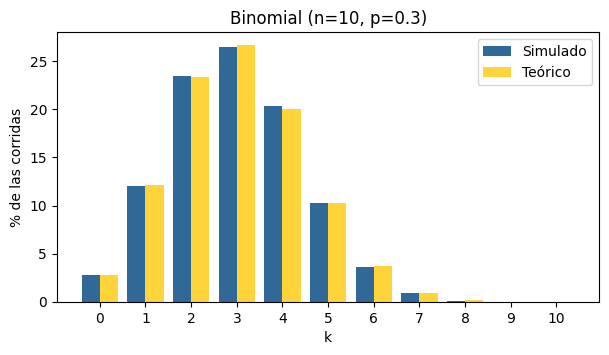

diferencia máxima: 0.36 puntos porcentuales


In [ ]:
# Mi predicción: ...

comparar(binom, range(0, 11), lambda k: t_binomial(k, 10, P), "Binomial (n=10, p=0.3)")

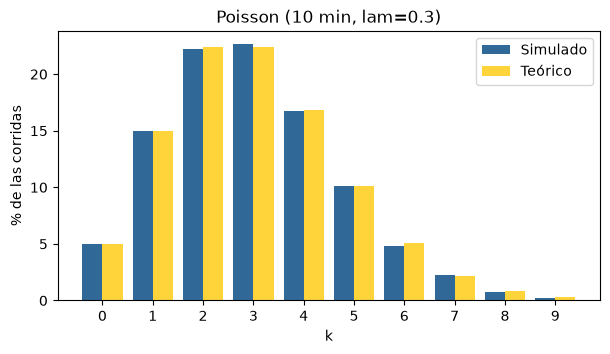

diferencia máxima: 0.27 puntos porcentuales


In [ ]:
comparar(poi, range(0, 10), lambda k: t_poisson(k, 3.0), "Poisson (10 min, lam=0.3)")

In [ ]:
comparar(geo, range(1, 11), lambda k: t_geometrica(k, P), "Geométrica (p=0.3)")

## 4. ¿Cuántas corridas? El error se encoge
Repetimos la binomial con distintos `N` (20 veces cada uno, y promediamos) y medimos la diferencia máxima contra la teoría.

**Predice:** si multiplico `N` por 100, ¿el error baja 100 veces, 10 veces o casi nada?

N=     100: error promedio = 5.49 puntos
N=    1000: error promedio = 1.86 puntos
N=   10000: error promedio = 0.58 puntos
N=  100000: error promedio = 0.18 puntos
N= 1000000: error promedio = 0.06 puntos


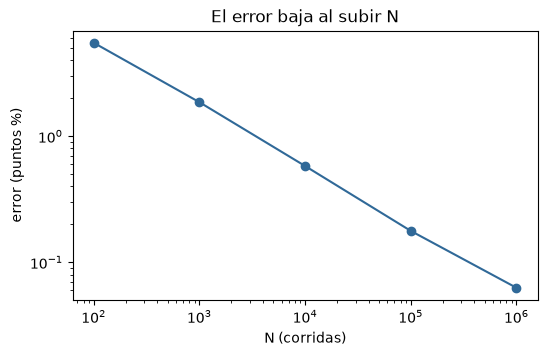

In [ ]:
# Mi predicción: ...

teo_b = np.array([100 * t_binomial(k, 10, P) for k in range(0, 11)])
tamanos = [100, 1000, 10000, 100000, 1000000]
errores = []

for n in tamanos:
    difs = []
    for _ in range(20):
        v = rng.binomial(10, P, size=n)
        difs.append(np.abs(freq(v, list(range(0, 11))) - teo_b).max())
    errores.append(np.mean(difs))
    print(f"N={n:>8}: error promedio = {errores[-1]:.2f} puntos")

plt.figure(figsize=(6, 3.5))
plt.loglog(tamanos, errores, marker="o", color="#306998")
plt.xlabel("N (corridas)")
plt.ylabel("error (puntos %)")
plt.title("El error baja al subir N")
plt.show()

Cada vez que `N` se multiplica por 100, el error baja unas **10 veces**. Esto conecta con lo de la primera hora: una sola corrida no alcanza, y mil veces más corridas no dan mil veces más precisión.

## 5. Poisson de dos maneras
Del miércoles: si los tiempos entre llegadas son exponenciales, los clientes que caben en 10 minutos salen Poisson. Aquí lo comprobamos con NumPy: sumamos tiempos `rng.exponential` y comparamos contra `rng.poisson`.

**Predice:** ¿darán el mismo promedio y la misma varianza?

In [ ]:
# Mi predicción: ...

def clientes_en(minutos, lam):
    t = rng.exponential(1 / lam)
    n = 0
    while t <= minutos:
        n += 1
        t += rng.exponential(1 / lam)
    return n


por_exp = np.array([clientes_en(10, 0.3) for _ in range(20000)])
print("sumando exponenciales: media", por_exp.mean().round(3), " var", por_exp.var().round(3))
print("rng.poisson          : media", poi.mean().round(3), " var", poi.var().round(3))

sumando exponenciales: media 3.001  var 2.966
rng.poisson          : media 2.996  var 2.988


## Actividad 8.1 — tu turno
Cambia los parámetros y repite lo de hoy. En cada tarea: **predicción** en un comentario, gráfica con `comparar` y una línea con lo que observas.

1. **Binomial** con `n = 20` y `p = 0.4`. ¿Cuál es el promedio esperado? Compáralo con el simulado.
2. **Geométrica** con `p = 0.1`. ¿Cuál es el valor más común y por qué? Estima la probabilidad de que el primer cliente tarde **más de 10 minutos** y compárala con `0.9 ** 10`.
3. **Poisson** con `lam = 7`. Compara promedio y varianza.
4. **Conclusión** (3 a 4 líneas): ¿qué cambia en la diferencia máxima si usas `N = 1000` en lugar de `N = 100 000`? ¿Por qué?

Entrega este notebook (`.ipynb`) en tu repo de GitHub; el link va en la plataforma.

In [ ]:
# Tarea 1
# Mi predicción: ...

In [ ]:
# Tarea 2
# Mi predicción: ...

In [ ]:
# Tarea 3
# Mi predicción: ...

In [ ]:
# Tarea 4
# Mi predicción: ...

**Conclusión:**